# Ergodicity: Ensemble Averages and Time Averages

When we work with a time series we usually observe **one** realization of a stochastic process: one history of GDP, one history of a stock price.
Still, we talk about quantities such as the expected value $E(x_t)$, which is defined as an average over **all possible** realizations of the process at a fixed point in time.
When can we learn something about the latter from the former? This is the question of ergodicity.

Imagine that we could run the process $N$ times independently and observe each run for $T$ periods. Let $x_t^{(i)}$ be the value of run (path) $i$ at time $t$. There are two natural ways to average:

- The **ensemble average** fixes the time $t$ and averages across the paths:

$$
\langle x_t \rangle_N = \frac{1}{N} \sum_{i = 1}^{N} x_t^{(i)}
$$

- The **time average** fixes one path $i$ and averages over time:

$$
\bar{x}_T^{(i)} = \frac{1}{T} \sum_{t = 1}^{T} x_t^{(i)}
$$

By the law of large numbers the ensemble average converges to the expected value $E(x_t)$ as $N \to \infty$ (the paths are independent).
The time average is different: the observations along one path are **dependent**, so it is not obvious that it converges at all, and if it does, to what.

**Definition (ergodicity for the mean).** A stationary process with $E(x_t) = \mu$ is *ergodic for the mean* if the time average of a single path converges to the ensemble mean:

$$
\bar{x}_T^{(i)} \to \mu \quad \text{as } T \to \infty .
$$

In this notebook we look at two examples:

1. A stationary AR(1) process with coefficient $0.7$, which is ergodic: one long path tells us everything about the ensemble.
2. A multiplicative betting game, which is not ergodic: the ensemble average grows while (almost) every single player goes broke.

## Where does the word come from?

The word *ergodic* comes from statistical physics. Ludwig Boltzmann introduced the term *Ergode* in the 1880s while studying gases, and Paul and Tatiana Ehrenfest made the name *ergodic hypothesis* popular in 1911. It is built from two Greek words:

- ἔργον (*ergon*): work, energy
- ὁδός (*hodos*): path, way

so *ergodic* means roughly "energy path". (An alternative reading derives the ending from εἶδος, *eidos*, "form" or "kind", so that an *Ergode* is something "energy-like". The first reading is the common one.)

The physical picture behind the name is the following. An isolated gas has a fixed total energy. Its microscopic state (the positions and velocities of all molecules) changes all the time, but it can only move among the states that have this energy.
Boltzmann's **ergodic hypothesis** says that the path of the system eventually passes through (or arbitrarily close to) *all* of these states, and spends equal time in regions of equal size.

If this is true, then two averages of a quantity such as the pressure must agree:

- the average over a long time for **one** system (what a measurement gives), and
- the average over **all states** with the given energy at one instant (what the theory can compute).

The second one is an average over an imagined collection of copies of the system, one for each possible state. Josiah Willard Gibbs called such a collection an *ensemble* (French for "together"), hence the name ensemble average.

The meaning carried over to time series analysis: a process is ergodic if a single path, followed long enough, visits all the states that the process can reach, in the right proportions. Then one path is representative of the whole ensemble.
A process is not ergodic when a path gets stuck in a part of the possible states or drifts away and never returns, so that different paths, or the same path at different times, tell different stories.

## An ergodic process: AR(1) with $\phi = 0.7$

Consider the AR(1) process

$$
x_t = c + \phi x_{t - 1} + e_t, \quad e_t \sim N(0, \sigma^2) \text{ independent over time}
$$

with $\phi = 0.7$, $c = 3$ and $\sigma = 1$.

**Assumption.** $|\phi| < 1$, so the process is stationary. Then

$$
\mu = E(x_t) = \frac{c}{1 - \phi} = 10, \qquad
\gamma_0 = Var(x_t) = \frac{\sigma^2}{1 - \phi^2} \approx 1.96, \qquad
\gamma_k = Cov(x_t, x_{t - k}) = \phi^k \gamma_0 .
$$

**Theorem (sufficient condition).** A stationary process with absolutely summable autocovariances, $\sum_{k = 0}^{\infty} |\gamma_k| < \infty$, is ergodic for the mean.

For the AR(1) process the condition holds, because the autocovariances decay geometrically:

$$
\sum_{k = 0}^{\infty} |\gamma_k| = \gamma_0 \sum_{k = 0}^{\infty} |\phi|^k = \frac{\gamma_0}{1 - |\phi|} < \infty .
$$

Intuitively, the process forgets its past: a shock that happened $k$ periods ago enters today's value with weight $0.7^k$.
Observations that are far apart in time are almost independent, so a long path behaves like many (nearly) independent draws.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters of the AR(1) process
phi = 0.7
constant = 3.0
sigma = 1.0

# Theoretical (ensemble) mean and variance
mean_theory = constant / (1 - phi)
variance_theory = sigma**2 / (1 - phi**2)

print(f"Theoretical mean:     {mean_theory:.2f}")
print(f"Theoretical variance: {variance_theory:.2f}")

Theoretical mean:     10.00
Theoretical variance: 1.96


We simulate $N = 2000$ independent paths, each of length $T = 1000$. The result is a matrix with one row per path and one column per time period.
Each path starts with a draw from the stationary distribution $N(\mu, \gamma_0)$, so that the process is stationary from the first period.

In [ ]:
def simulate_ar1(n_paths, n_periods, rng):
    # Simulate independent AR(1) paths. Rows are paths, columns are time periods.
    paths = np.zeros((n_paths, n_periods))

    # Start every path with a draw from the stationary distribution
    paths[:, 0] = rng.normal(mean_theory, np.sqrt(variance_theory), size=n_paths)

    for t in range(1, n_periods):
        shocks = rng.normal(0, sigma, size=n_paths)
        paths[:, t] = constant + phi * paths[:, t - 1] + shocks

    return paths


rng = np.random.default_rng(2026)

n_paths = 2000
n_periods = 1000

ar1_paths = simulate_ar1(n_paths, n_periods, rng)
ar1_paths.shape

(2000, 1000)

### Ensemble average

For the ensemble average we fix a time period (a column of the matrix) and average over all paths (rows).

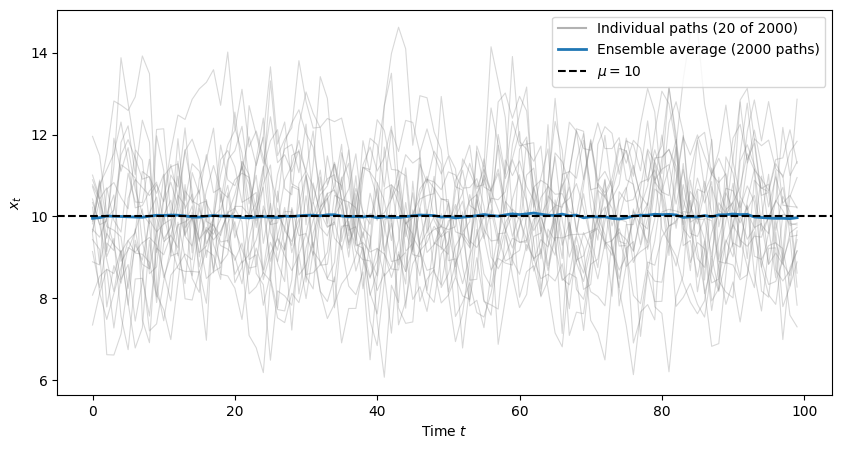

In [ ]:
#| label: fig-ar1-ensemble
#| fig-cap: "AR(1): a few individual paths and the ensemble average over 2000 paths"

# Average over the paths (axis 0) for every time period
ar1_ensemble_average = ar1_paths.mean(axis=0)

periods_shown = 100

plt.figure(figsize=(10, 5))
plt.plot(ar1_paths[:20, :periods_shown].T, color="gray", alpha=0.3, linewidth=0.8)
plt.plot([], [], color="gray", alpha=0.6, label="Individual paths (20 of 2000)")
plt.plot(ar1_ensemble_average[:periods_shown], color="tab:blue", linewidth=2,
         label="Ensemble average (2000 paths)")
plt.axhline(mean_theory, color="black", linestyle="--", label=r"$\mu = 10$")
plt.xlabel("Time $t$")
plt.ylabel("$x_t$")
plt.legend()
plt.show()

The individual paths fluctuate a lot, but the ensemble average is close to $\mu = 10$ in every period.

### Time average

For the time average we fix a path (a row of the matrix) and average over time. To see the convergence we compute the *running* time average

$$
\bar{x}_t^{(i)} = \frac{1}{t} \sum_{s = 1}^{t} x_s^{(i)}, \quad t = 1, \ldots, T
$$

for a few paths.

**Approximation.** For large $t$ the variance of the time average of an AR(1) process is approximately

$$
Var\left(\bar{x}_t\right) \approx \frac{1}{t} \cdot \frac{\sigma^2}{(1 - \phi)^2}
$$

so it shrinks to zero at rate $1/t$. The approximation is valid for $|\phi| < 1$ and $t$ large relative to the memory of the process (here a few dozen periods). The shaded band in the plot shows $\mu \pm 2 \sqrt{Var(\bar{x}_t)}$.

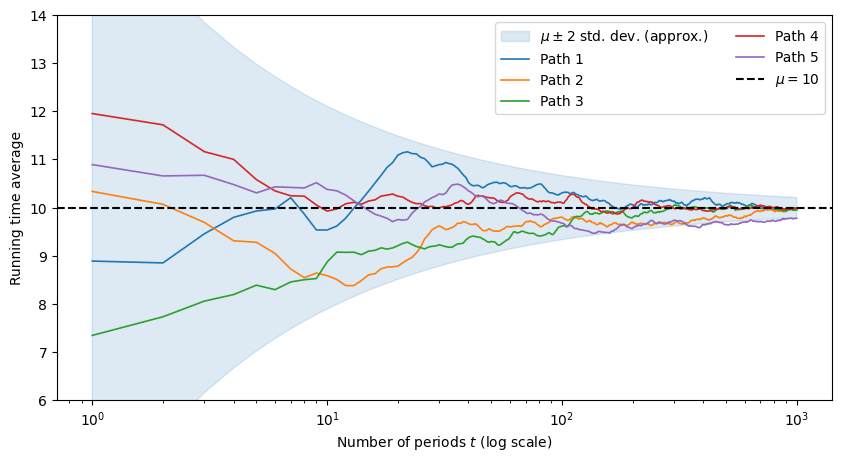

In [4]:
#| label: fig-ar1-time-average
#| fig-cap: "AR(1): running time averages of five individual paths"

time_index = np.arange(1, n_periods + 1)

# Running time average of every path: cumulative sum divided by the number of periods
ar1_running_time_average = ar1_paths.cumsum(axis=1) / time_index

# Approximate standard deviation of the time average (large t)
time_average_std = sigma / ((1 - phi) * np.sqrt(time_index))

plt.figure(figsize=(10, 5))
plt.fill_between(time_index,
                 mean_theory - 2 * time_average_std,
                 mean_theory + 2 * time_average_std,
                 color="tab:blue", alpha=0.15, label=r"$\mu \pm 2$ std. dev. (approx.)")
for path_number in range(5):
    plt.plot(time_index, ar1_running_time_average[path_number], linewidth=1.2,
             label=f"Path {path_number + 1}")
plt.axhline(mean_theory, color="black", linestyle="--", label=r"$\mu = 10$")
plt.xscale("log")
plt.ylim(6, 14)
plt.xlabel("Number of periods $t$ (log scale)")
plt.ylabel("Running time average")
plt.legend(ncol=2)
plt.show()

Every path starts somewhere else, but all running time averages converge to the same number, the ensemble mean $\mu = 10$.

Let us compare the numbers directly.

In [5]:
print(f"Theoretical mean:                         {mean_theory:.3f}")
print(f"Ensemble average at the last period:      {ar1_paths[:, -1].mean():.3f}")
print(f"Time average of path 1 ({n_periods} periods):    {ar1_paths[0].mean():.3f}")
print(f"Time average of path 2 ({n_periods} periods):    {ar1_paths[1].mean():.3f}")

Theoretical mean:                         10.000
Ensemble average at the last period:      10.008
Time average of path 1 (1000 periods):    9.979
Time average of path 2 (1000 periods):    9.950


### One long path looks like the ensemble

The same holds for the whole distribution, not only for the mean. The left histogram shows the values of **all paths at one point in time** (a column of the matrix).
The right histogram shows the values of **one path over all periods** (a row). Both match the stationary distribution $N(\mu, \gamma_0)$.

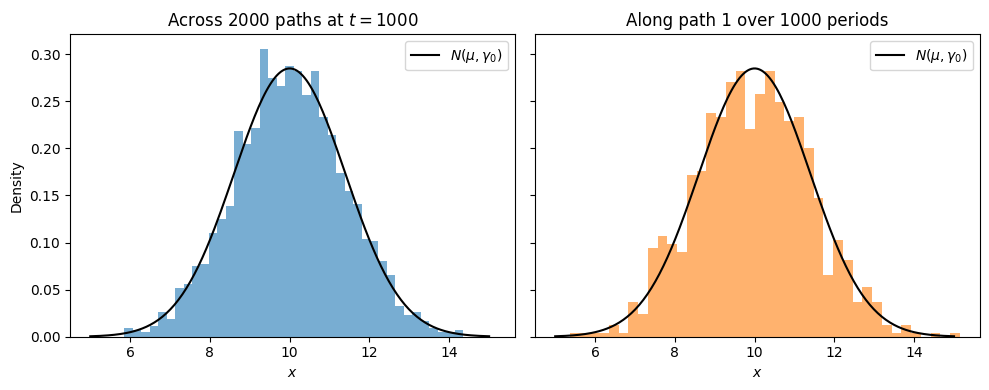

In [6]:
#| label: fig-ar1-distributions
#| fig-cap: "AR(1): distribution across paths at a fixed time and distribution over time for a single path"

grid = np.linspace(mean_theory - 5, mean_theory + 5, 200)
stationary_density = (
    np.exp(-(grid - mean_theory)**2 / (2 * variance_theory))
    / np.sqrt(2 * np.pi * variance_theory)
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)

axes[0].hist(ar1_paths[:, -1], bins=40, density=True, color="tab:blue", alpha=0.6)
axes[0].set_title(f"Across {n_paths} paths at $t = {n_periods}$")

axes[1].hist(ar1_paths[0], bins=40, density=True, color="tab:orange", alpha=0.6)
axes[1].set_title(f"Along path 1 over {n_periods} periods")

for ax in axes:
    ax.plot(grid, stationary_density, color="black", label=r"$N(\mu, \gamma_0)$")
    ax.set_xlabel("$x$")
    ax.legend()

axes[0].set_ylabel("Density")
plt.tight_layout()
plt.show()

This is what makes time series analysis possible: for an ergodic process we can estimate ensemble quantities like $\mu$ from the single path that we actually observe.

## A non-ergodic process: multiplicative betting

Now consider the following game. You start with wealth $W_0 = 100$. In every round a fair coin is tossed:

- heads: your wealth increases by 50% (it is multiplied by $1.5$),
- tails: your wealth decreases by 40% (it is multiplied by $0.6$).

You always bet your whole wealth, so

$$
W_t = W_{t - 1} \cdot f_t, \qquad
f_t = \begin{cases} 1.5 & \text{with probability } 0.5 \\ 0.6 & \text{with probability } 0.5 \end{cases}
$$

with independent tosses. Should you play?

**Ensemble view.** The expected growth factor per round is

$$
E(f_t) = 0.5 \cdot 1.5 + 0.5 \cdot 0.6 = 1.05
$$

and because the tosses are independent

$$
E(W_t) = W_0 \cdot 1.05^t .
$$

On average over all players the wealth grows by 5% per round. The game looks attractive.

**Time view.** A single player who plays $T$ rounds and sees $H$ heads ends up with $W_T = W_0 \cdot 1.5^{H} \cdot 0.6^{T - H}$.
By the law of large numbers $H / T \to 0.5$, so the growth factor per round of a single path converges to

$$
\left(\frac{W_T}{W_0}\right)^{1 / T} = 1.5^{H / T} \cdot 0.6^{1 - H / T} \to 1.5^{0.5} \cdot 0.6^{0.5} = \sqrt{0.9} \approx 0.949 .
$$

Over time a single player **loses** about 5.1% per round. One round of heads followed by one round of tails turns 100 into $100 \cdot 1.5 \cdot 0.6 = 90$.

The two averages give opposite answers, so the wealth process is not ergodic. It is convenient to state this in terms of growth rates (logs):

$$
\underbrace{\frac{1}{t} \ln \frac{E(W_t)}{W_0} = \ln 1.05 \approx 0.049}_{\text{ensemble growth rate}}
\qquad \text{but} \qquad
\underbrace{\frac{1}{T} \ln \frac{W_T}{W_0} \to E(\ln f_t) = \frac{1}{2} \ln 0.9 \approx -0.053}_{\text{time-average growth rate}}
$$

In [7]:
# Parameters of the betting game
up_factor = 1.5
down_factor = 0.6
probability_up = 0.5
initial_wealth = 100.0

# Growth rates per round
ensemble_growth_rate = np.log(probability_up * up_factor + (1 - probability_up) * down_factor)
time_growth_rate = probability_up * np.log(up_factor) + (1 - probability_up) * np.log(down_factor)

print(f"Ensemble growth rate, ln E(f):     {ensemble_growth_rate: .4f}")
print(f"Time-average growth rate, E(ln f): {time_growth_rate: .4f}")

Ensemble growth rate, ln E(f):      0.0488
Time-average growth rate, E(ln f): -0.0527


In [8]:
def simulate_betting(n_players, n_rounds, rng):
    # Simulate wealth paths. Rows are players, columns are rounds 0, 1, ..., n_rounds.
    heads = rng.random((n_players, n_rounds)) < probability_up
    factors = np.where(heads, up_factor, down_factor)

    wealth = np.empty((n_players, n_rounds + 1))
    wealth[:, 0] = initial_wealth
    wealth[:, 1:] = initial_wealth * factors.cumprod(axis=1)

    return wealth

### Ensemble average

We let $N = 100\,000$ players play 30 rounds each and compute the ensemble average of their wealth in every round.
Next to it we plot the median, i.e. the wealth of the "typical" player.

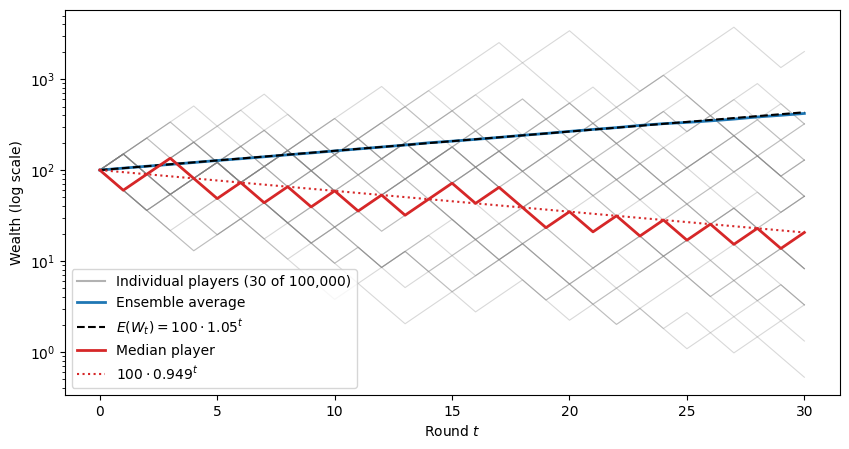

In [9]:
#| label: fig-betting-ensemble
#| fig-cap: "Betting game: ensemble average and median wealth of 100,000 players"

rng = np.random.default_rng(123)

n_players = 100_000
n_rounds_ensemble = 30

wealth_ensemble = simulate_betting(n_players, n_rounds_ensemble, rng)
rounds_ensemble = np.arange(n_rounds_ensemble + 1)

plt.figure(figsize=(10, 5))
plt.plot(rounds_ensemble, wealth_ensemble[:30].T, color="gray", alpha=0.3, linewidth=0.8)
plt.plot([], [], color="gray", alpha=0.6, label="Individual players (30 of 100,000)")
plt.plot(rounds_ensemble, wealth_ensemble.mean(axis=0), color="tab:blue", linewidth=2,
         label="Ensemble average")
plt.plot(rounds_ensemble, initial_wealth * np.exp(ensemble_growth_rate * rounds_ensemble),
         color="black", linestyle="--", label=r"$E(W_t) = 100 \cdot 1.05^t$")
plt.plot(rounds_ensemble, np.median(wealth_ensemble, axis=0), color="tab:red", linewidth=2,
         label="Median player")
plt.plot(rounds_ensemble, initial_wealth * np.exp(time_growth_rate * rounds_ensemble),
         color="tab:red", linestyle=":", label=r"$100 \cdot 0.949^t$")
plt.yscale("log")
plt.xlabel("Round $t$")
plt.ylabel("Wealth (log scale)")
plt.legend()
plt.show()

The ensemble average follows $100 \cdot 1.05^t$, exactly as the expected value predicts. But the median player is far below and follows $100 \cdot 0.949^t$ instead. (The zigzag of the median appears because the number of heads needed to be at the median alternates between odd and even rounds.)
The ensemble average is carried by a small number of very lucky players:

In [10]:
final_wealth = wealth_ensemble[:, -1]
top_one_percent = np.sort(final_wealth)[-n_players // 100:]

print(f"Ensemble average after {n_rounds_ensemble} rounds:     {final_wealth.mean():8.1f}")
print(f"Expected value 100 * 1.05^{n_rounds_ensemble}:         {initial_wealth * 1.05**n_rounds_ensemble:8.1f}")
print(f"Median wealth:                         {np.median(final_wealth):8.1f}")
print(f"Share of players below their start:    {np.mean(final_wealth < initial_wealth):8.1%}")
print(f"Share of total wealth held by top 1%:  {top_one_percent.sum() / final_wealth.sum():8.1%}")

Ensemble average after 30 rounds:        419.3
Expected value 100 * 1.05^30:            432.2
Median wealth:                             20.6
Share of players below their start:       71.1%
Share of total wealth held by top 1%:     51.2%


**Note on the simulation.** The ensemble average over a *finite* number of players tracks $E(W_t)$ only for a limited number of rounds.
The relative variance of $W_t$ grows like $(E(f_t^2) / E(f_t)^2)^t \approx 1.18^t$, so for long horizons even $100\,000$ players are too few and the sample average falls below $1.05^t$.
This is why we use only 30 rounds here.

### Time average

Now we follow single players for a long time: 2000 rounds.

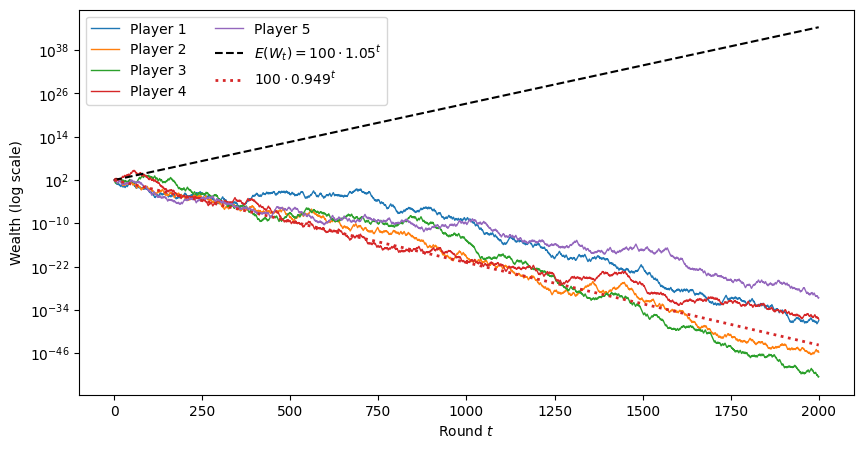

In [11]:
#| label: fig-betting-paths
#| fig-cap: "Betting game: wealth of five players over 2000 rounds"

rng = np.random.default_rng(321)

n_rounds_time = 2000
wealth_time = simulate_betting(5, n_rounds_time, rng)
rounds_time = np.arange(n_rounds_time + 1)

plt.figure(figsize=(10, 5))
for player_number in range(5):
    plt.plot(rounds_time, wealth_time[player_number], linewidth=1,
             label=f"Player {player_number + 1}")
plt.plot(rounds_time, initial_wealth * np.exp(ensemble_growth_rate * rounds_time),
         color="black", linestyle="--", label=r"$E(W_t) = 100 \cdot 1.05^t$")
plt.plot(rounds_time, initial_wealth * np.exp(time_growth_rate * rounds_time),
         color="tab:red", linestyle=":", linewidth=2, label=r"$100 \cdot 0.949^t$")
plt.yscale("log")
plt.xlabel("Round $t$")
plt.ylabel("Wealth (log scale)")
plt.legend(ncol=2)
plt.show()

Every player is eventually ruined, although the expected wealth explodes. As for the AR(1) process we plot the running time average, here of the growth rate:

$$
g_t^{(i)} = \frac{1}{t} \ln \frac{W_t^{(i)}}{W_0}
$$

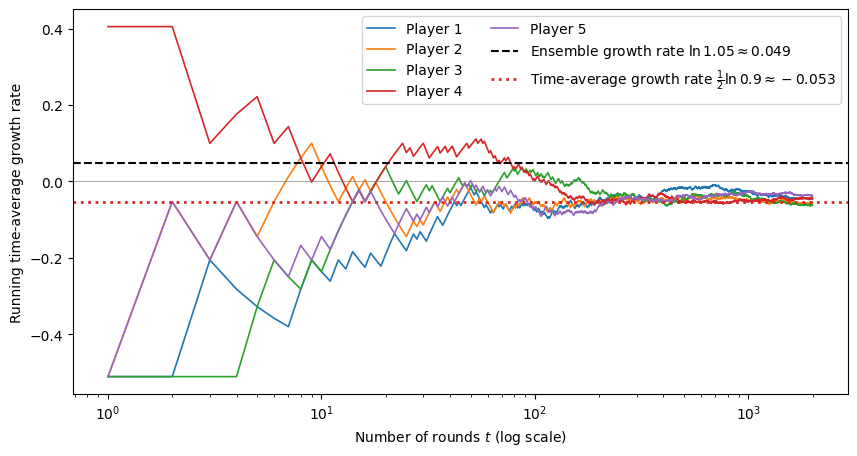

In [12]:
#| label: fig-betting-growth-rate
#| fig-cap: "Betting game: running time-average growth rates of five players"

# Running time-average growth rate (skip round 0 to avoid dividing by zero)
running_growth_rate = np.log(wealth_time[:, 1:] / initial_wealth) / rounds_time[1:]

plt.figure(figsize=(10, 5))
for player_number in range(5):
    plt.plot(rounds_time[1:], running_growth_rate[player_number], linewidth=1.2,
             label=f"Player {player_number + 1}")
plt.axhline(ensemble_growth_rate, color="black", linestyle="--",
            label=r"Ensemble growth rate $\ln 1.05 \approx 0.049$")
plt.axhline(time_growth_rate, color="tab:red", linestyle=":", linewidth=2,
            label=r"Time-average growth rate $\frac{1}{2}\ln 0.9 \approx -0.053$")
plt.axhline(0, color="gray", linewidth=0.5)
plt.xscale("log")
plt.xlabel("Number of rounds $t$ (log scale)")
plt.ylabel("Running time-average growth rate")
plt.legend(ncol=2)
plt.show()

All players converge to the same growth rate, but it is $-0.053$ and not the ensemble growth rate $+0.049$.
Compare this with @fig-ar1-time-average, where the time averages converged to the ensemble mean.

## Why the difference?

| | AR(1) with $\phi = 0.7$ | Multiplicative betting |
|---|---|---|
| Dynamics | additive shocks, $x_t = c + \phi x_{t-1} + e_t$ | multiplicative shocks, $W_t = W_{t-1} f_t$ |
| Effect of a shock after $k$ periods | dies out as $0.7^k$ | permanent |
| Stationary | yes | no |
| Ensemble average | $\mu = 10$ | grows like $1.05^t$ |
| Time average of a single path | converges to $\mu = 10$ | growth factor converges to $0.949 < 1$ |
| Ergodic | yes | no |

Taking logs of the betting game gives

$$
\ln W_t = \ln W_{t - 1} + \ln f_t
$$

This is an AR(1) process with coefficient $\phi = 1$: a random walk with drift $E(\ln f_t) \approx -0.053$.
The stationarity assumption $|\phi| < 1$ fails, shocks never die out, and the autocovariances are not summable.

Note that the *increments* $\ln f_t$ are independent and identically distributed and therefore ergodic.
This is exactly why the time-average growth rate of every player converges to $E(\ln f_t)$. To find out what happens to a single player over time, the right quantity to average is $\ln f_t$ and not $f_t$.